<a href="https://colab.research.google.com/github/IvanRUDN/IST2026_autumn/blob/main/SVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_squared_error
from skimage import data
from skimage.transform import resize

# Берём готовую цветную картинку
img = data.astronaut()
img = resize(img, (400, 400), anti_aliasing=True)
img = (img * 255).astype(np.uint8)

original = img.astype(float)
original_shape = img.shape
h, w, c = original_shape

print('Размер изображения:', original_shape)

Размер изображения: (400, 400, 3)


## SVD и восстановление изображения

In [2]:
# SVD для трёх цветовых каналов
U_list = []
s_list = []
Vt_list = []

for channel in range(3):
    U, s, Vt = np.linalg.svd(original[:, :, channel], full_matrices=False)
    U_list.append(U)
    s_list.append(s)
    Vt_list.append(Vt)

# Обязательные ранги
list_of_ranks = [1, 5, 10, 30, 100, min(h, w)]
approximations = []
compression_list = []
mse_list = []

original_size = h * w * 3

for r in list_of_ranks:
    result = np.zeros_like(original)

    for channel in range(3):
        result[:, :, channel] = (U_list[channel][:, :r] * s_list[channel][:r]) @ Vt_list[channel][:r, :]

    result = np.clip(result, 0, 255)
    approximations.append(result)

    # Размер сжатого представления в float32
    compressed_size = 3 * r * (h + 1 + w) * 4
    compression = original_size / compressed_size
    compression_list.append(compression)

    mse = mean_squared_error(original.flatten(), result.flatten())
    mse_list.append(mse)

print('Готово')

Готово


## Результаты

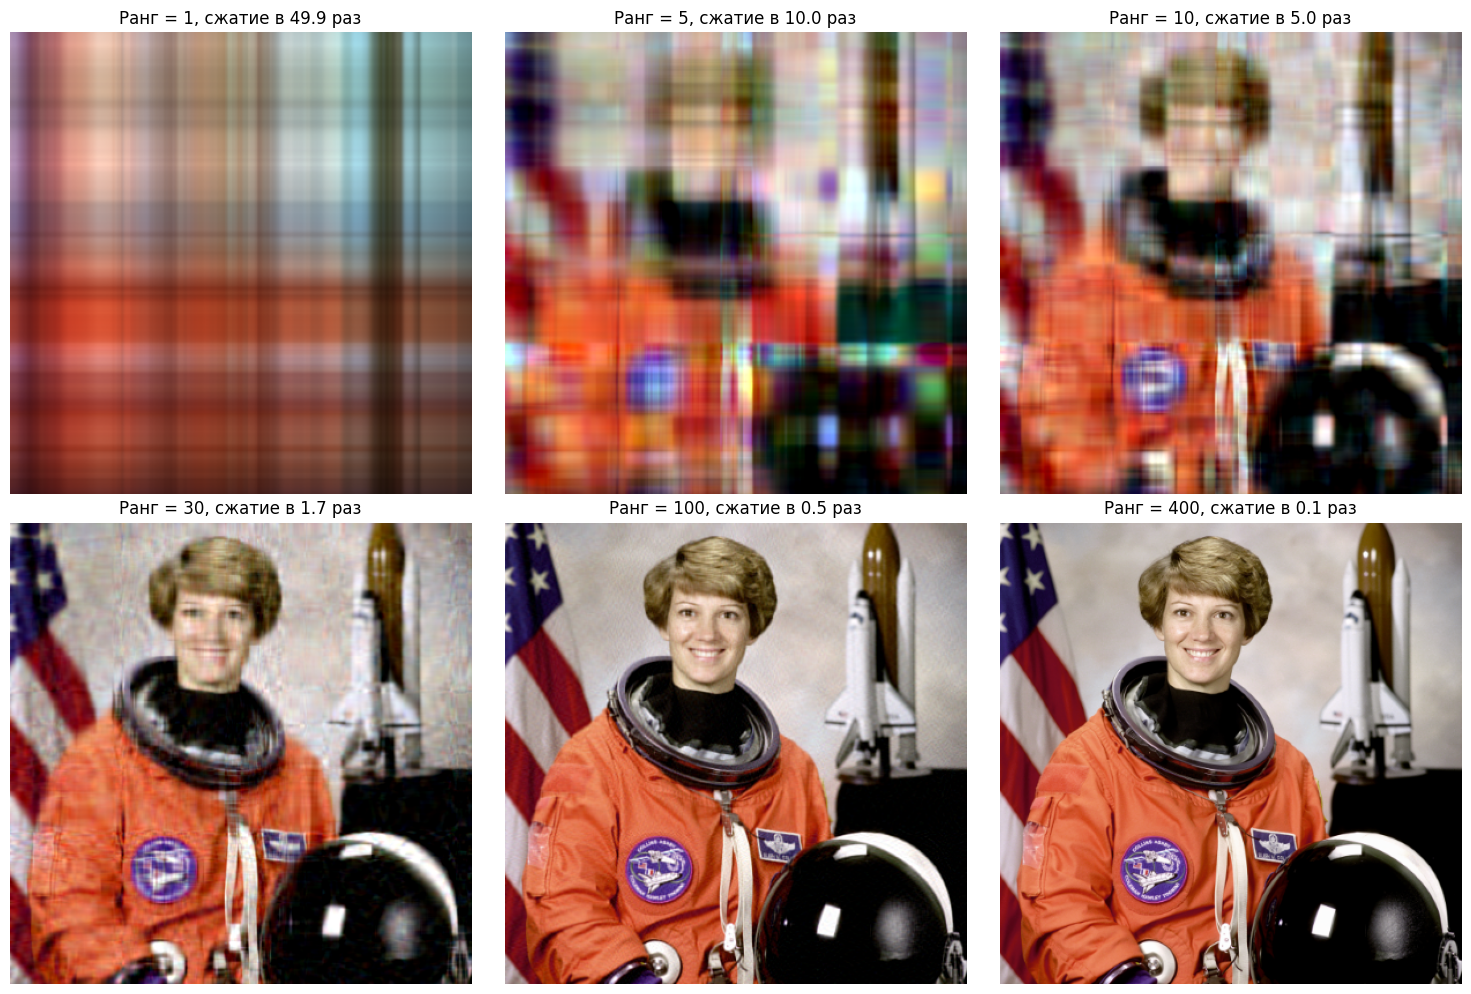

In [3]:
plt.figure(figsize=(15, 10))

for i, r in enumerate(list_of_ranks):
    plt.subplot(2, 3, i + 1)
    plt.imshow(approximations[i].astype(np.uint8))
    plt.title(f'Ранг = {r}, сжатие в {compression_list[i]:.1f} раз')
    plt.axis('off')

plt.tight_layout()
plt.show()

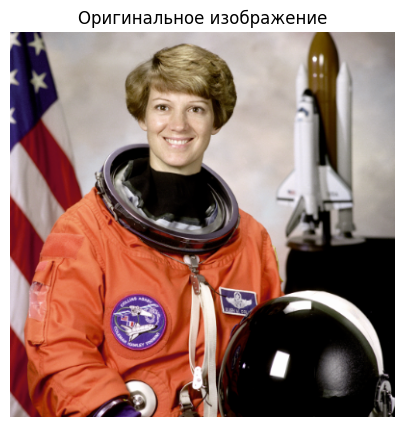

In [4]:
# Оригинал
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title('Оригинальное изображение')
plt.axis('off')
plt.show()

## Таблица результатов

In [5]:
print('Ранг | Сжатие | MSE')
print('-' * 30)
for r, compression, mse in zip(list_of_ranks, compression_list, mse_list):
    print(f'{r:4} | {compression:7.2f} | {mse:.2f}')

Ранг | Сжатие | MSE
------------------------------
   1 |   49.94 | 4163.28
   5 |    9.99 | 1505.76
  10 |    4.99 | 752.22
  30 |    1.66 | 197.48
 100 |    0.50 | 18.25
 400 |    0.12 | 0.00


## Автопроверка

Проверяем размер изображений, диапазон значений и уменьшение MSE.

In [6]:
# ---------- БЛОК АВТОПРОВЕРКИ ----------
for i, r in enumerate(list_of_ranks):
    assert approximations[i].shape == original_shape

for i, r in enumerate(list_of_ranks):
    arr = np.clip(approximations[i], 0, 255)
    assert arr.max() <= 255.1
    assert arr.min() >= -0.1

for i in range(1, len(mse_list)):
    assert mse_list[i] <= mse_list[i-1] + 1e-6

print('✅ Все проверки пройдены')

✅ Все проверки пройдены
